In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

import joblib

In [2]:
import warnings

warnings.filterwarnings("ignore")

In [3]:
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

pd.set_option("display.max_columns", None)

In [4]:
df = pd.read_csv("medical_insurance.csv")

In [5]:
df.shape

(2772, 7)

In [6]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2772 entries, 0 to 2771
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       2772 non-null   int64  
 1   sex       2772 non-null   object 
 2   bmi       2772 non-null   float64
 3   children  2772 non-null   int64  
 4   smoker    2772 non-null   object 
 5   region    2772 non-null   object 
 6   charges   2772 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 151.7+ KB


In [8]:
df.isna().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [9]:
df.describe()

,age,bmi,children,charges
count,2772.000000,2772.000000,2772.000000,2772.000000
mean,39.109668,30.701349,1.101732,13261.369959
std,14.081459,6.129449,1.214806,12151.768945
min,18.000000,15.960000,0.000000,1121.873900
25%,26.000000,26.220000,0.000000,4687.797000
50%,39.000000,30.447500,1.000000,9333.014350
75%,51.000000,34.770000,2.000000,16577.779500
max,64.000000,53.130000,5.000000,63770.428010


In [10]:
df.duplicated().sum()

np.int64(1435)

In [11]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [18]:
dup_counts = df.groupby(list(df.columns)).size().reset_index(name ='count')

In [20]:
dup_counts["count"].value_counts()

count
2    1288
4      49
Name: count, dtype: int64

In [21]:
df = df.drop_duplicates().reset_index(drop = True)
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1332,50,male,30.970,3,no,northwest,10600.54830
1333,18,female,31.920,0,no,northeast,2205.98080
1334,18,female,36.850,0,no,southeast,1629.83350
1335,21,female,25.800,0,no,southwest,2007.94500


In [22]:
for col in ["sex", "smoker", "region"]:
    print(f"-----{col}-----")
    print(df[col].value_counts())
    print(df[col].value_counts(normalize=True).round(3))

-----sex-----
sex
male      675
female    662
Name: count, dtype: int64
sex
male      0.505
female    0.495
Name: proportion, dtype: float64
-----smoker-----
smoker
no     1063
yes     274
Name: count, dtype: int64
smoker
no     0.795
yes    0.205
Name: proportion, dtype: float64
-----region-----
region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64
region
southeast    0.272
southwest    0.243
northwest    0.242
northeast    0.242
Name: proportion, dtype: float64


In [27]:
for col in ["age", "bmi", "children", "charges"]:
    print(f"{col}: skew= {df[col].skew():.3f}, kurtosis= {df[col].kurt():.3f}")

age: skew= 0.055, kurtosis= -1.244
bmi: skew= 0.284, kurtosis= -0.053
children: skew= 0.937, kurtosis= 0.201
charges: skew= 1.515, kurtosis= 1.604


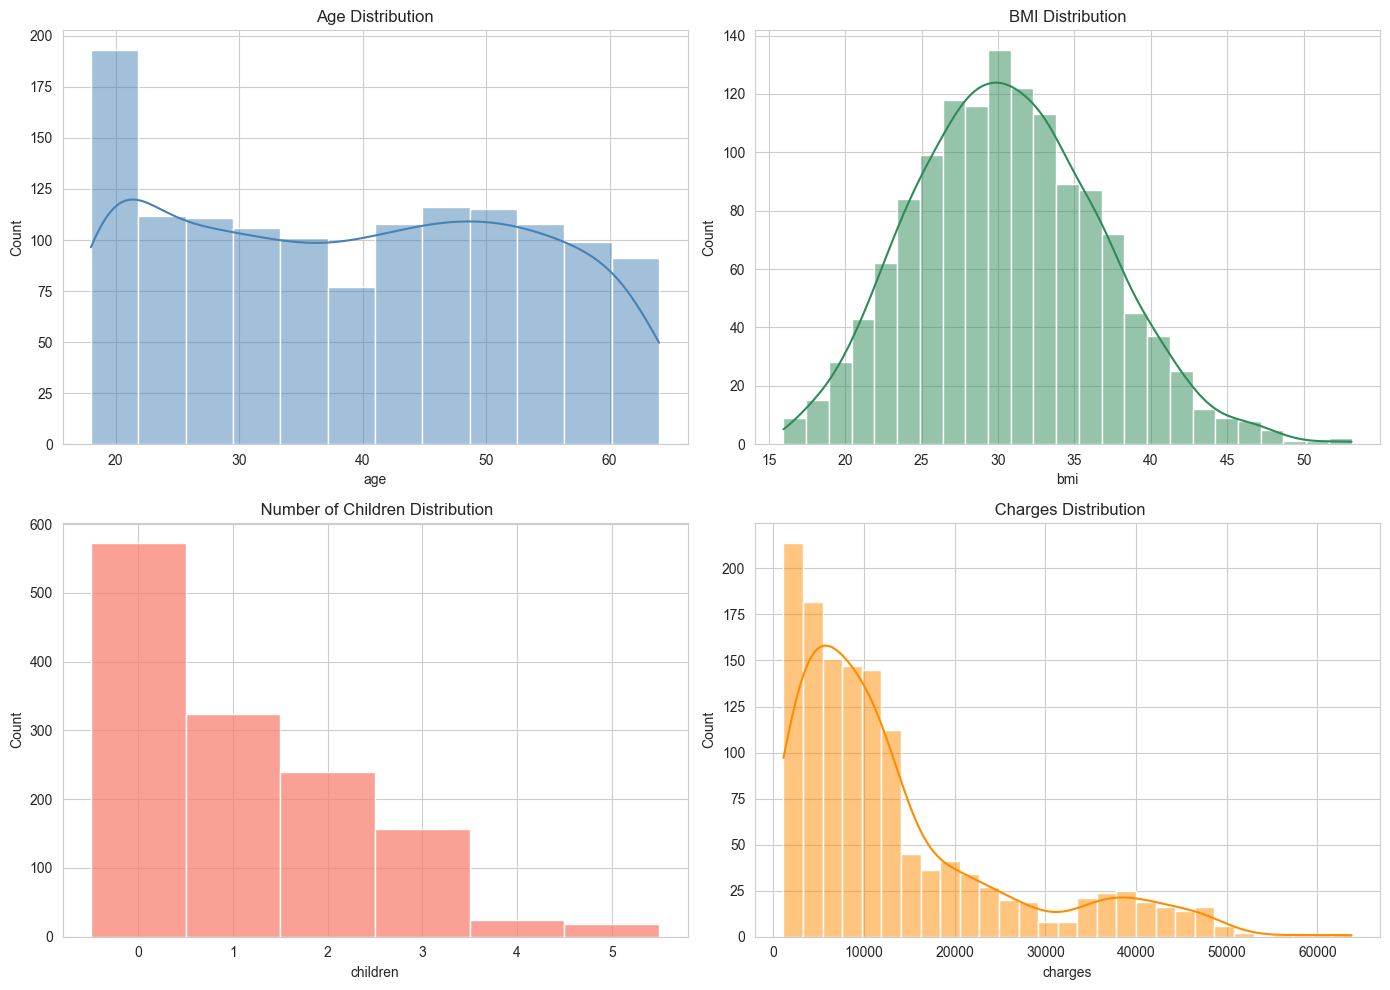

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(14,10))

sns.histplot(df["age"], kde=True, ax = axes[0,0], color = "steelblue")
axes[0,0].set_title("Age Distribution")

sns.histplot(df["bmi"], kde=True, ax = axes[0,1], color = "seagreen")
axes[0,1].set_title("BMI Distribution")

sns.histplot(df["children"], discrete=True, ax = axes[1,0], color = "salmon")
axes[1,0].set_title(" Number of Children Distribution")

sns.histplot(df["charges"], kde=True, ax = axes[1,1], color = "darkorange")
axes[1,1].set_title(" Charges Distribution")

plt.tight_layout()

plt.show()


In [33]:
for col in ["bmi", "charges"]:

    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

    n_out = ((df[col] < lower) | (df[col] > upper)).sum()

    print(f"{col}: bounds = ({lower:.1f}, {upper:.1f}, outliers = {n_out} ({n_out/len(df) * 100: .1f}%))")
    

bmi: bounds = (13.7, 47.3, outliers = 9 ( 0.7%))
charges: bounds = (-13120.7, 34524.8, outliers = 139 ( 10.4%))


In [34]:
df.groupby("smoker")["charges"].agg(["mean", "median", "std", "count"])

,mean,median,std,count
smoker,,,,
no,8440.660307,7345.72660,5992.973800,1063
yes,32050.231832,34456.34845,11541.547176,274


In [35]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [36]:
def bmi_category(bmi):
    if bmi < 18.5:
        return "underweight"
    elif bmi < 25:
        return "normal"
    elif bmi < 30:
        return "overweight"
    else:
        return "obese"
        

In [37]:
df["bmi_category"] = df["bmi"].apply(bmi_category)

In [38]:
df.head()

,age,sex,bmi,children,smoker,region,charges,bmi_category
0,19,female,27.900,0,yes,southwest,16884.92400,overweight
1,18,male,33.770,1,no,southeast,1725.55230,obese
2,28,male,33.000,3,no,southeast,4449.46200,obese
3,33,male,22.705,0,no,northwest,21984.47061,normal
4,32,male,28.880,0,no,northwest,3866.85520,overweight


In [39]:
df["bmi_category"].value_counts()

bmi_category
obese          706
overweight     386
normal         225
underweight     20
Name: count, dtype: int64

In [41]:
df.groupby("bmi_category")["charges"].mean().sort_values().round(2)

bmi_category
underweight     8852.20
normal         10409.34
overweight     10987.51
obese          15572.04
Name: charges, dtype: float64

In [42]:
df["log_charges"] = np.log1p(df["charges"])
df.head()

,age,sex,bmi,children,smoker,region,charges,bmi_category,log_charges
0,19,female,27.900,0,yes,southwest,16884.92400,overweight,9.734236
1,18,male,33.770,1,no,southeast,1725.55230,obese,7.453882
2,28,male,33.000,3,no,southeast,4449.46200,obese,8.400763
3,33,male,22.705,0,no,northwest,21984.47061,normal,9.998137
4,32,male,28.880,0,no,northwest,3866.85520,overweight,8.260455


In [43]:
df["charges"].skew()

np.float64(1.5153909108403483)

In [44]:
df["log_charges"].skew()

np.float64(-0.08955835073325419)

### Encoding categorical variables

In [50]:
df_model = pd.get_dummies(
    df,
    columns = ["sex", "smoker", "region", "bmi_category"],
    drop_first = True
)

print(df_model.columns.to_list())

['age', 'bmi', 'children', 'charges', 'log_charges', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest', 'bmi_category_obese', 'bmi_category_overweight', 'bmi_category_underweight']


In [51]:
df_model.head()

,age,bmi,children,charges,log_charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest,bmi_category_obese,bmi_category_overweight,bmi_category_underweight
0,19,27.900,0,16884.92400,9.734236,False,True,False,False,True,False,True,False
1,18,33.770,1,1725.55230,7.453882,True,False,False,True,False,True,False,False
2,28,33.000,3,4449.46200,8.400763,True,False,False,True,False,True,False,False
3,33,22.705,0,21984.47061,9.998137,True,False,True,False,False,False,False,False
4,32,28.880,0,3866.85520,8.260455,True,False,True,False,False,False,True,False


In [49]:
feature_cols = [c for c in df_model.columns if c not in ["charges", "log_charges"]]

X = df_model[feature_cols]

y = df_model["log_charges"]

In [54]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)                                         

In [56]:
y_test_real = np.expm1(y_test)
# inverse transition of the y-test

candidate_models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators = 300, max_depth=6, n_jobs= -1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators= 300, max_depth= 3, learning_rate= 0.05)
}

trained_models = {}
metrics_rows = []

for name, model in candidate_models.items():

    model.fit(X_train, y_train)
    y_pred_log = model.predict(X_test)
    y_pred = np.expm1(y_pred_log)

    r2 = r2_score(y_test_real, y_pred)
    mae = mean_absolute_error(y_test_real, y_pred)
    rmse  = np.sqrt(mean_squared_error(y_test_real, y_pred))

    trained_models[name] = model
    metrics_rows.append({"Model": name, "R2": r2, "MAE": mae, "RMSE": rmse})

    print(f"{name} --> R2: {r2:.4f} -- MAE: {mae:.2f} -- RMSE: {rmse:.2f}")

Linear Regression --> R2: 0.4999 -- MAE: 4254.09 -- RMSE: 8253.79
Random Forest --> R2: 0.8504 -- MAE: 1958.03 -- RMSE: 4513.95
Gradient Boosting --> R2: 0.8157 -- MAE: 2308.84 -- RMSE: 5010.62


In [60]:
results = pd.DataFrame(metrics_rows).sort_values("R2", ascending=False).reset_index(drop=True)
results

,Model,R2,MAE,RMSE
0,Random Forest,0.850418,1958.028947,4513.952564
1,Gradient Boosting,0.815690,2308.839836,5010.615490
2,Linear Regression,0.499882,4254.093994,8253.792161


In [62]:
best_model_name = results.loc[0, "Model"]
best_model = trained_models[best_model_name]

In [63]:
best_model_name

'Random Forest'

In [64]:
best_model

,n_estimators,300
,criterion,'squared_error'
,max_depth,6
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [66]:
joblib.dump(best_model, "insurance_model.pkl")
joblib.dump(feature_cols, "model_features.pkl")
joblib.dump(best_model_name, "model_name.pkl")

['model_name.pkl']